# Introduction

In this tutorial, we demonstrate how to use **SpatialZoomer** to identify multi-scale spatial structures in high-resolution spatial transcriptomics (ST) data, ranging from local bins to niches and tissue domains.  

For illustration, we use the officially provided 8 µm binned output from a Visium HD fresh frozen mouse brain sample (453,820 bins, 19,059 genes). Visium HD is a sequencing-based, high-resolution ST technology. The recorded analysis took approximately 70 minutes.

#### Table of Contents
- [0. Installation, package loading, and data preprocessing](#0-installation-package-loading-and-data-preprocessing)
- [1. Extract multi-scale features via spectral graph signal processing](#1-extract-multi-scale-features-via-spectral-graph-signal-processing)
- [2. Identify critical scales automatically](#2-identify-critical-scales-automatically)
- [3. Identify spatial structures using two-step clustering](#3-identify-spatial-structures-using-two-step-clustering)
  - [Results and Analysis](#results-and-analysis)
  - [Results in the save_path Folder](#results-in-the-save_path-folder)

### 0. Installation, package loading, and data preprocessing

For detailed installation instructions, environment setup, and package dependencies, please refer to the [SpatialZoomer GitHub repository](https://github.com/Li-Xinqi/SpatialZoomer.git).

Install or upgrade to the latest version of SpatialZoomer:

```bash
python -m pip install --upgrade spatialzoomer
```

Import the installed package:

```python
import spatialzoomer as sz
```

Next, load the spatial transcriptomics data, perform bin- and gene-level quality control, and normalize the expression matrix.

In [1]:
import warnings
warnings.filterwarnings("ignore")

# Load packages
import spatialzoomer as sz 
import numpy as np
import scanpy as sc
import seaborn as sns
import os
import matplotlib.pyplot as plt

# Set figure parameters
plt.rcParams.update({
    "font.family":'sans-serif',
    "mathtext.fontset":'stix',
    "font.size": 7,
    'pdf.fonttype': 42,
    "figure.dpi": 80,      
    "savefig.dpi": 300      
    })
use_dpi = 80 

Please set the following basic information:
* `runLabel`: The name of the dataset.

* `save_path`: A path to save the analysis results.

* `adata`: An **AnnData** object storing the officially provided Visium HD 8 µm binned mouse brain data,  

  - `adata.X` contains the raw, unnormalized transcript count matrix.  
  
  - `adata.obsm['spatial']` stores the spatial coordinates of the bins.  
 
The **input ST data** in AnnData format are available in the current Zenodo archive and can also be downloaded from [Google Drive](https://drive.google.com/file/d/1yN4i2p0ZrhLwhiRxZVqUVhfyltKKDpbH/view?usp=drive_link).

The original data can be downloaded from the [official Visium HD dataset page](https://www.10xgenomics.com/datasets/visium-hd-cytassist-gene-expression-mouse-brain-fresh-frozen).

In [2]:
runLabel = 'Visium_HD_Mouse_Brain_Fresh_Frozen'
save_path = './Outputs/' + runLabel+'_SpatialZoomer/'
if not os.path.exists(save_path):
    os.makedirs(save_path)
adata = sc.read_h5ad("./" + runLabel+ "_adata_binned8um.h5ad")
adata

AnnData object with n_obs × n_vars = 453820 × 19059
    obs: 'in_tissue', 'array_row', 'array_col', 'location_id', 'region'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatialdata_attrs'
    obsm: 'spatial'

<Axes: title={'center': 'Unique transcripts per cell'}, xlabel='n_genes_by_counts', ylabel='Count'>

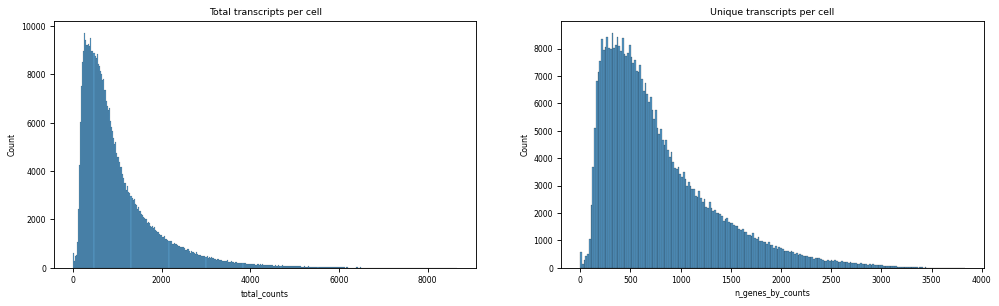

In [3]:
sc.pp.calculate_qc_metrics(adata, percent_top=(10, 20, 50, 150), inplace=True)
fig, axs = plt.subplots(1, 2, figsize=(15, 4))

axs[0].set_title("Total transcripts per cell")
sns.histplot(
    adata.obs["total_counts"],
    kde=False,
    ax=axs[0],
)

axs[1].set_title("Unique transcripts per cell")
sns.histplot(
    adata.obs["n_genes_by_counts"],
    kde=False,
    ax=axs[1],
)

**Quality control and normalization**

* `filter_cells` removes low-quality bins with insufficient transcript and gene detection;
* `filter_genes` removes genes detected in too few bins;
* `sz.Preprocess` stores the original count matrix in `adata.layers["counts"]`, performs total-count normalization, and applies a log(1+x) transformation.

In [4]:
# Quality control on cells
sc.pp.filter_cells(adata, min_counts = 100)
sc.pp.filter_cells(adata, min_genes = 50)

# Quality control on genes
sc.pp.filter_genes(adata, min_cells = 50)

# Normalization
adata = sz.Preprocess(adata)
adata

AnnData object with n_obs × n_vars = 451697 × 15056
    obs: 'in_tissue', 'array_row', 'array_col', 'location_id', 'region', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes', 'n_counts', 'n_genes'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'spatialdata_attrs', 'log1p'
    obsm: 'spatial'
    layers: 'counts'

### 1. Extract multi-scale features via spectral graph signal processing

- Obtain **graph signals** from transcriptomic data using dimensionality reduction with **NMF**.

- Construct a **spatial neighbor graph** based on the physical proximity of bins.

- Apply a bank of **heat-kernel-based low-pass filters** to extract features across multiple spatial scales.

Perform NMF to obtain graph signals. `n_components` specifies the dimensionality of the graph signals.

In [5]:
adata = sz.performDR(adata, type = 'NMF', n_components=50)
adata

Time taken to perform NMF: 2984.4032 seconds


AnnData object with n_obs × n_vars = 451697 × 15056
    obs: 'in_tissue', 'array_row', 'array_col', 'location_id', 'region', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes', 'n_counts', 'n_genes'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'spatialdata_attrs', 'log1p'
    obsm: 'spatial', 'X_nmf'
    varm: 'nmf_loadings'
    layers: 'counts'

Initialize the SpatialZoomer object and define a set of candidate scales.

Here, `save_intermediate=False` reduces storage use by not saving the transformed-signal `.h5` file or intermediate K-Means `.h5ad` objects.

In [6]:
sz_analyzer = sz.MultiscaleAnalysis(adata=adata, runLabel=runLabel, save_path=save_path, save_intermediate = False)
 
scales = [0.01] \
    + np.arange(0.1, 2.1, 0.1).tolist() \
    + np.arange(2.5, 15.5, 0.5).tolist() \
    + np.arange(16, 21, 1).tolist() \
    +  np.arange(25, 55, 5).tolist()
scales = [round(x, 2) for x in scales]

In [7]:
sz_analyzer.dpi = use_dpi

Perform spectral graph signal processing to extract multi-scale features:

- `use_rep`: selects graph signals from `adata.obsm`; here we use `X_nmf` (NMF-transformed data)

- `n_neighbors`: number of neighbors in the spatial neighbor graph

- `scales`: candidate scales defined above

### 2. Identify critical scales automatically

SpatialZoomer partitions the cross-scale similarity map into contiguous blocks and automatically selects critical scales representing the transitions and centers of these blocks. `max_clusters` and `min_clusters` specify the range of possible block numbers.

Median similarities:  4.999999999991449
Time taken to construct spatial_knn: 6.1889 seconds
Time taken to perform spectral graph filter bank: 244.8210 seconds


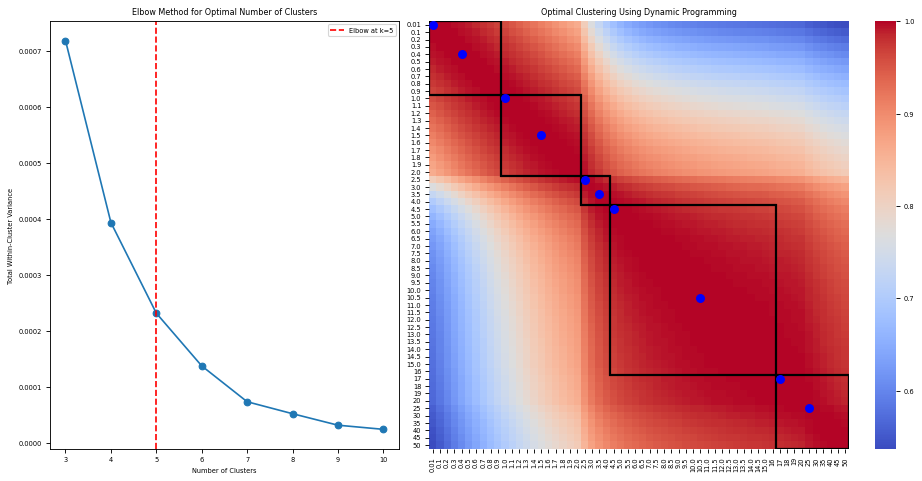

The optimal number of clusters is: 5
Typical scales: [0.01, 0.4, 1.0, 1.5, 2.5, 3.5, 4.5, 10.5, 17, 25]
Time taken to perform identification of typical scales: 21.0852 seconds


In [8]:
sz_analyzer.multiscale_transform(use_rep='X_nmf', n_neighbors=20, scales=scales)
sz_analyzer.identify_typical_scales(max_clusters=10, min_clusters=3)

### 3. Identify spatial structures using two-step clustering

Clustering is performed in two steps:

1. **Mini-Batch K-Means** is applied to the transformed signals at each selected scale to obtain 10,000 metacells representing groups of bins.

2. **Leiden clustering** is applied to the metacells. A higher resolution yields more clusters.

**Recommendation:** test multiple resolution values and select the setting that matches biological expectations and downstream tasks.

In [9]:
resolutions = [0.8, 1, 1.2]
sz_analyzer.clustering(n_clusters_kmeans=10000, resolutions=resolutions)

Time taken to perform UMAP and clustering for raw signal: 142.4198 seconds
Time taken to perform clustering for signal at scale 0.01: 79.3230 seconds
Time taken to perform clustering for signal at scale 0.4: 83.8137 seconds
Time taken to perform clustering for signal at scale 1.0: 83.5042 seconds
Time taken to perform clustering for signal at scale 1.5: 83.7671 seconds
Time taken to perform clustering for signal at scale 2.5: 80.6782 seconds
Time taken to perform clustering for signal at scale 3.5: 78.5963 seconds
Time taken to perform clustering for signal at scale 4.5: 81.6411 seconds
Time taken to perform clustering for signal at scale 10.5: 69.6683 seconds
Time taken to perform clustering for signal at scale 17.0: 76.6806 seconds
Time taken to perform clustering for signal at scale 25.0: 68.6780 seconds
Total time: 787.9252 seconds


The clustering and UMAP results at each critical scale are stored in `sz_analyzer.adata`.

- **Clustering results** are stored in `sz_analyzer.adata.obs`, with keys formatted as `leiden_<scale>_res<resolution>`.

- **UMAP embeddings** are stored in `sz_analyzer.adata.obsm`, with keys formatted as `X_umap_<scale>`.

In [10]:
sz_analyzer.adata

AnnData object with n_obs × n_vars = 451697 × 15056
    obs: 'in_tissue', 'array_row', 'array_col', 'location_id', 'region', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes', 'n_counts', 'n_genes', 'Kmeans_Raw', 'leiden_Raw_res0.8', 'leiden_Raw_res1', 'leiden_Raw_res1.2', 'Kmeans_scale0.01', 'leiden_scale0.01_res0.8', 'leiden_scale0.01_res1', 'leiden_scale0.01_res1.2', 'Kmeans_scale0.4', 'leiden_scale0.4_res0.8', 'leiden_scale0.4_res1', 'leiden_scale0.4_res1.2', 'Kmeans_scale1.0', 'leiden_scale1.0_res0.8', 'leiden_scale1.0_res1', 'leiden_scale1.0_res1.2', 'Kmeans_scale1.5', 'leiden_scale1.5_res0.8', 'leiden_scale1.5_res1', 'leiden_scale1.5_res1.2', 'Kmeans_scale2.5', 'leiden_scale2.5_res0.8', 'leiden_scale2.5_res1', 'leiden_scale2.5_res1.2', 'Kmeans_scale3.5', 'leiden_scale3.5_res0.8', 'leiden_scale3.5_res1', 'leiden_scale3.5_res1.

### Results and Analysis

- In the **raw signal space** (Scale 0.0), clustering reflects the local 8 µm-bin scale.

- **As the scale increases**, each bin progressively integrates spatial context from broader neighborhoods, capturing spatial structures such as niches and tissue domains.

- At excessively large scales, signals become over-smoothed and may no longer preserve meaningful biological distinctions.

Note: Results may slightly differ from those reported in the paper because NMF, Leiden, and UMAP involve randomness. Although random seeds are set, minor variations can still occur across environments or devices.

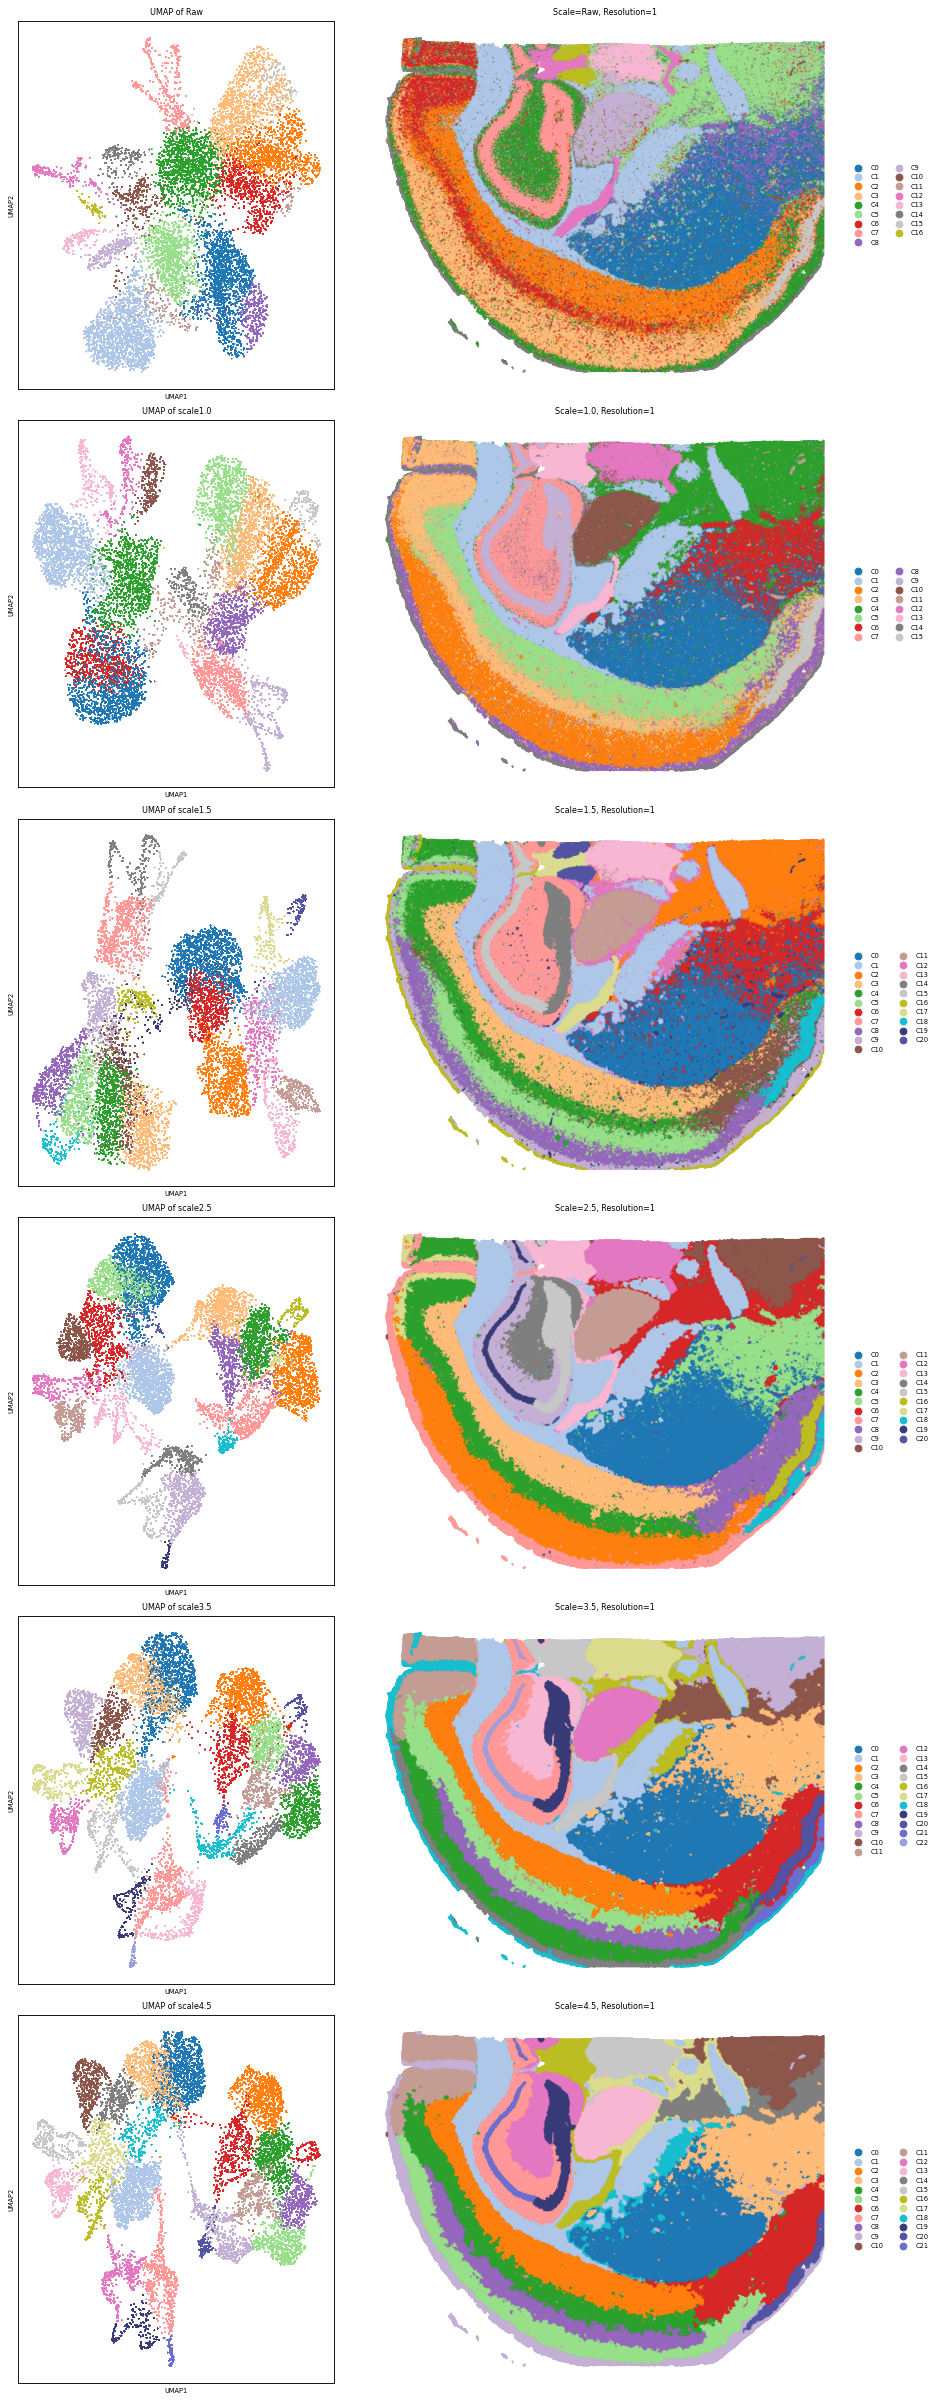

In [11]:
sz_analyzer.plot_multiscale_clusters(resolution=1, min_scale = 0.5, max_scale = 8)

Quantify the contributions of spatial proximity and transcriptomic similarity to clustering outcomes across different scales.

The `sz_analyzer.adata` object is compatible with the Python ecosystem for scRNA-seq and ST data, including packages such as **scanpy** and **squidpy**, and can be used directly for downstream analysis and visualization.

In [12]:
sz_analyzer.adata.write(save_path + runLabel + '_SpatialZoomer.h5ad')

Median similarities:  4.999999994042879
Time taken to construct expr_knn: 31.2023 seconds


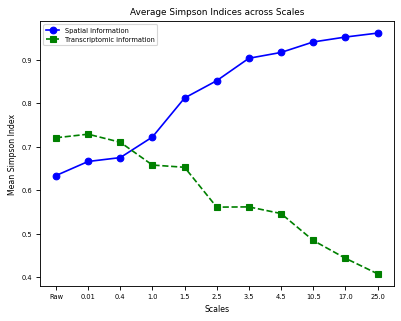

In [13]:
sz_analyzer.plot_simpson()

### Results in the `save_path` folder

The following output files are generated and saved in the `save_path` directory:

- `<runLabel>_SpatialZoomer.h5ad`: The core AnnData object containing all multi-scale clustering results, recommended for downstream analyses.

- `Typical_scales.pdf`: Visualization of critical scale selection, generated by `identify_typical_scales()`.  

- `Typical_scales.csv`: Data frame recording the selected critical scales.  

- `Average_Simpson_Indices_across_Scales.pdf`: Output of `plot_simpson()`, which quantifies the contributions of spatial proximity and transcriptomic similarity to clustering results across scales.